# 03 Evaluate: how good are the forecasts in the backtest?

**Purpose:** Compute the backtest errors of all candidate models, per horizon, in units a planner understands; compare the models at the main horizon ($h = 2$), also without the crisis periods and year by year; check whether the route indicator helps.
**Input:** `../data/processed/backtest_forecasts.csv` (from `02_estimate.ipynb`), `../data/processed/backtest_forecasts_regression.csv` (from `02b_estimate_regression.ipynb`) and `../data/processed/backtest_forecasts_indicator.csv` (from `02c_estimate_indicator.ipynb`).
**Output:** `../output/tables/03_backtest_errors.csv`, `../output/tables/03_backtest_errors_by_year_h2.csv`, `../output/tables/03_indicator_effect.csv` and two figures in `../output/figures/`.

This notebook uses **only the backtest** (2013 to September 2024). The test period stays untouched until we have chosen our final model (notebook 209, Step 7: choose before you test).

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

np.random.seed(42)
plt.style.use("seaborn-v0_8-muted")

## 1. Load the forecasts and compute the errors

For every forecast we compute two errors:

- the **absolute error in persons**, $|y - \hat y|$: the mean of it (MAE) says by how many applications per month we miss on average. This is the number a planner at SEM understands (notebook 108b, deck 08; notebook 209, Step 8).
- the **squared error in logs**, $(\log y - \widehat{\log y})^2$: the root of its mean (RMSE in logs) is the error measure of our project plan. An error of 0.10 in logs is roughly 10% off (notebook 209).

In [2]:
# The forecasts of the three estimation notebooks, stacked one below the other (pd.concat, notebook 04)
forecasts_sarima = pd.read_csv("../data/processed/backtest_forecasts.csv")
forecasts_regression = pd.read_csv("../data/processed/backtest_forecasts_regression.csv").drop(columns=["alpha"])
forecasts_indicator = pd.read_csv("../data/processed/backtest_forecasts_indicator.csv").drop(columns=["alpha"])
forecasts = pd.concat([forecasts_sarima, forecasts_regression, forecasts_indicator], ignore_index=True)
forecasts["month"] = pd.to_datetime(forecasts["month"])
forecasts["origin"] = pd.to_datetime(forecasts["origin"])

forecasts["abs_error"] = (forecasts["actual"] - forecasts["forecast"]).abs()
forecasts["sq_error_log"] = (forecasts["actual_log"] - forecasts["forecast_log"]) ** 2

print("Forecasts:", forecasts.shape[0], "| models:", forecasts["model"].nunique(),
      "| forecast months from", forecasts["month"].min(), "to", forecasts["month"].max())

Forecasts: 4620 | models: 11 | forecast months from 2013-01-01 00:00:00 to 2024-09-01 00:00:00


## 2. Errors of all models for all horizons

We put the two simple rules first, then the three (S)ARIMA models (`02_estimate.ipynb`), the three regression models on the series' own past (`02b_estimate_regression.ipynb`), and the same three regressions with the route indicator (`02c_estimate_indicator.ipynb`). All eleven models were evaluated on exactly the same forecast months (notebook 209: the same folds and the same error measure for all).

In [3]:
model_order = ["Seasonal naive", "12-month average",
               "ARIMA(1,1,0)", "SARIMA(1,1,0)(1,0,0)12", "SARIMA(0,1,1)(0,1,1)12",
               "Linear regression", "Ridge", "Lasso",
               "Linear regression + routes", "Ridge + routes", "Lasso + routes"]
baselines = ["Seasonal naive", "12-month average"]
sarima_models = ["ARIMA(1,1,0)", "SARIMA(1,1,0)(1,0,0)12", "SARIMA(0,1,1)(0,1,1)12"]
regression_models = ["Linear regression", "Ridge", "Lasso"]
indicator_models = ["Linear regression + routes", "Ridge + routes", "Lasso + routes"]

# One fixed colour per model, the same in every figure (plt.cm.tab10, notebook 211).
# A model "+ routes" gets the colour of the same model without the indicator (and a dashed line below).
colors = dict(zip(model_order[:8], plt.cm.tab10(np.arange(8))))
for name in regression_models:
    colors[name + " + routes"] = colors[name]

def error_table(data):
    # MAE in persons and RMSE in logs for every model and horizon
    grouped = data.groupby(["model", "h"])
    table = pd.DataFrame({
        "MAE (persons)": grouped["abs_error"].mean(),
        "RMSE (log)": np.sqrt(grouped["sq_error_log"].mean()),
        "forecasts": grouped["abs_error"].size(),
    }).reset_index()
    return table

errors = error_table(forecasts)

mae = errors.pivot(index="model", columns="h", values="MAE (persons)").loc[model_order].round(0)
mae.columns = [f"MAE h={h}" for h in mae.columns]
rmse = errors.pivot(index="model", columns="h", values="RMSE (log)").loc[model_order].round(3)
rmse.columns = [f"RMSE log h={h}" for h in rmse.columns]

overview = pd.concat([mae, rmse], axis=1)
overview.to_csv("../output/tables/03_backtest_errors.csv")
overview

,MAE h=1,MAE h=2,MAE h=3,RMSE log h=1,RMSE log h=2,RMSE log h=3
model,,,,,,
Seasonal naive,679.0,681.0,682.0,0.436,0.437,0.438
12-month average,487.0,528.0,558.0,0.317,0.342,0.362
"ARIMA(1,1,0)",272.0,388.0,499.0,0.207,0.292,0.361
"SARIMA(1,1,0)(1,0,0)12",260.0,371.0,468.0,0.199,0.282,0.347
"SARIMA(0,1,1)(0,1,1)12",254.0,369.0,458.0,0.191,0.274,0.328
Linear regression,256.0,358.0,452.0,0.197,0.278,0.333
Ridge,248.0,358.0,447.0,0.187,0.279,0.336
Lasso,254.0,360.0,450.0,0.193,0.281,0.338
Linear regression + routes,266.0,373.0,483.0,0.203,0.282,0.340


**What we see.**
- At every horizon, the two simple rules have the largest errors: the seasonal naive about 680 persons, the 12-month average 487 to 558. All six models that use the series' own past are far below them.
- These six models are close to each other. At $h = 2$, their MAE lies between 358 and 388 persons: the three regressions are at 358, 358 and 360, the best SARIMA at 369, ARIMA(1,1,0) at 388.
- The two error measures do not crown the same model. By MAE, Ridge is lowest at all three horizons (248, 358, 447). By RMSE in logs, SARIMA(0,1,1)(0,1,1)12 is lowest at $h = 2$ (0.274) and $h = 3$ (0.328), and Ridge at $h = 1$ (0.187).
- As before, the seasonal naive has almost the same error at every horizon, because its forecast is always the value 12 months earlier, whatever the origin.
- The three regressions **with the route indicator** (last three rows) are a little worse than the same regressions without it: at $h = 2$ their MAE is 364 to 374 against 358 to 360. We look at this in detail in section 7.

## 3. The main comparison: $h = 2$

Our project plan fixes one main comparison (Johannes' feedback): the **best simple baseline** against the **best model**, at the main horizon $h = 2$, by MAE in persons. We read all of them from the table above with code, so that nothing is chosen by hand. We also print the best model of each family.

In [4]:
h2 = errors[errors["h"] == 2].set_index("model")

best_baseline = h2.loc[baselines, "MAE (persons)"].idxmin()
best_sarima = h2.loc[sarima_models, "MAE (persons)"].idxmin()
best_regression = h2.loc[regression_models, "MAE (persons)"].idxmin()
best_indicator = h2.loc[indicator_models, "MAE (persons)"].idxmin()
best_model = h2.loc[sarima_models + regression_models + indicator_models, "MAE (persons)"].idxmin()

for label, name in [("Best simple baseline", best_baseline), ("Best (S)ARIMA model", best_sarima),
                    ("Best regression model", best_regression), ("Best model with routes", best_indicator),
                    ("Best model overall", best_model)]:
    print(f"{label + ' at h=2:':28s} {name:27s} MAE {h2.loc[name, 'MAE (persons)']:5.1f} persons   "
          f"RMSE (log) {h2.loc[name, 'RMSE (log)']:.3f}")

mae_base, mae_best = h2.loc[best_baseline, "MAE (persons)"], h2.loc[best_model, "MAE (persons)"]
rmse_base, rmse_best = h2.loc[best_baseline, "RMSE (log)"], h2.loc[best_model, "RMSE (log)"]
print()
print(f"Improvement of the best model over the best baseline: {100 * (1 - mae_best / mae_base):.0f}% lower MAE, "
      f"{100 * (1 - rmse_best / rmse_base):.0f}% lower RMSE (log)")
average_actual = forecasts[forecasts["h"] == 2]["actual"].mean()
print(f"For comparison, average actual number of applications in these months: {average_actual:.0f}")

Best simple baseline at h=2: 12-month average            MAE 527.7 persons   RMSE (log) 0.342
Best (S)ARIMA model at h=2:  SARIMA(0,1,1)(0,1,1)12      MAE 369.0 persons   RMSE (log) 0.274
Best regression model at h=2: Ridge                       MAE 357.9 persons   RMSE (log) 0.279
Best model with routes at h=2: Ridge + routes              MAE 364.1 persons   RMSE (log) 0.281
Best model overall at h=2:   Ridge                       MAE 357.9 persons   RMSE (log) 0.279

Improvement of the best model over the best baseline: 32% lower MAE, 18% lower RMSE (log)
For comparison, average actual number of applications in these months: 1850


**What we see.**
- The best simple baseline is the 12-month average (MAE 527.7 persons, RMSE 0.342). The best model overall, by MAE, is Ridge (357.9 persons, RMSE 0.279): **32% lower MAE** and 18% lower RMSE (log) than the 12-month average. For comparison, there were on average 1,850 applications per month in these months.
- Ridge is only 11 applications per month better than the best SARIMA model (369.0): about 3%. By RMSE (log), the SARIMA model is slightly better (0.274 against 0.279). The plain linear regression has practically the same MAE as Ridge (358 in the table above).
- The best model with the route indicator is Ridge + routes (364.1), so adding the indicator does not change the best model.

**What this means for us.** Using the series' own past clearly beats the simple rules, by far more than the 10% of our success rule. Between the regressions and SARIMA, there is no clear winner: Ridge's gain over SARIMA is far below 10%, and the other error measure points the other way. The six own-history models, at about 358 to 369 persons, are the benchmark that an indicator block must beat.

## 4. Without the crisis periods

The backtest contains two exceptional periods: the 2015-16 crisis and the drop of 2020. As planned, we report the errors also without the forecast months of these years (2015-01 to 2016-12 and 2020-01 to 2020-12), and for the recent years only (from 2022). These are **evaluation periods**: the models themselves did not know about them.

In [5]:
month = forecasts["month"]
crisis = ((month >= "2015-01-01") & (month <= "2016-12-01")) | ((month >= "2020-01-01") & (month <= "2020-12-01"))

periods = {
    "all backtest months": forecasts,
    "without 2015-16 and 2020": forecasts[~crisis],
    "from 2022": forecasts[month >= "2022-01-01"],
}

rows = []
for period_name, data in periods.items():
    table = error_table(data[data["h"] == 2])
    table["period"] = period_name
    rows.append(table)
by_period = pd.concat(rows)

by_period.pivot(index="model", columns="period", values="MAE (persons)").loc[model_order, list(periods)].round(0)

period,all backtest months,without 2015-16 and 2020,from 2022
model,,,
Seasonal naive,681.0,523.0,681.0
12-month average,528.0,369.0,512.0
"ARIMA(1,1,0)",388.0,304.0,496.0
"SARIMA(1,1,0)(1,0,0)12",371.0,281.0,450.0
"SARIMA(0,1,1)(0,1,1)12",369.0,295.0,427.0
Linear regression,358.0,286.0,413.0
Ridge,358.0,282.0,415.0
Lasso,360.0,288.0,420.0
Linear regression + routes,373.0,291.0,412.0


In [6]:
# Number of forecast months in each period (h = 2)
by_period[by_period["model"] == "Seasonal naive"].set_index("period")["forecasts"]

period
all backtest months         140
without 2015-16 and 2020    104
from 2022                    33
Name: forecasts, dtype: int64

**What we see.** (The three periods contain 140, 104 and 33 forecast months.)
- Without 2015-16 and 2020, all errors are smaller. The best own-history models are SARIMA(1,1,0)(1,0,0)12 (281) and Ridge (282), against 369 for the 12-month average: the gap to the simple rule shrinks from 170 to 88 persons.
- From 2022, the linear regression (413) and Ridge (415) are lowest, before the best SARIMA (427), and the 12-month average is at 512.
- The models with the route indicator are a little worse than their versions without it in the first two periods. From 2022, the linear regression + routes is equal to the linear regression (412 against 413), while Ridge and Lasso + routes are worse (436 and 431).

**What this means for us.** The best own-history model changes from one period to the next: the regressions and the (S)ARIMA models trade places. Their differences are small compared with how much the errors change between periods.

## 5. Is the difference real, or within the noise? Year by year

Notebook 209 compares models fold by fold: each validation fold gives one error, and we look at whether the gap between two models is larger than the spread across the folds, and whether one model wins in most folds. In a time-series backtest, the natural "folds" are the **years**: we compute the MAE at $h = 2$ for each year of forecast months (2013 to 2024; 2013 starts in February and 2024 ends in September).

*Not seen in class:* `forecasts["month"].dt.year` gives the year of each forecast month.

In [7]:
h2_all = forecasts[forecasts["h"] == 2].copy()
h2_all["year"] = h2_all["month"].dt.year

by_year = h2_all.groupby(["year", "model"])["abs_error"].mean().reset_index()
by_year = by_year.pivot(index="year", columns="model", values="abs_error")[model_order].round(0)
by_year.columns.name = None
by_year.to_csv("../output/tables/03_backtest_errors_by_year_h2.csv")
by_year

,Seasonal naive,12-month average,"ARIMA(1,1,0)","SARIMA(1,1,0)(1,0,0)12","SARIMA(0,1,1)(0,1,1)12",Linear regression,Ridge,Lasso,Linear regression + routes,Ridge + routes,Lasso + routes
year,,,,,,,,,,,
2013,640.0,392.0,189.0,193.0,216.0,244.0,207.0,234.0,226.0,211.0,227.0
2014,520.0,464.0,472.0,483.0,486.0,453.0,472.0,459.0,482.0,482.0,488.0
2015,1398.0,1501.0,762.0,812.0,787.0,730.0,704.0,668.0,782.0,629.0,666.0
2016,1727.0,1187.0,832.0,785.0,703.0,692.0,746.0,762.0,770.0,794.0,830.0
2017,760.0,430.0,205.0,145.0,183.0,162.0,161.0,170.0,194.0,180.0,182.0
2018,237.0,171.0,129.0,124.0,187.0,166.0,148.0,174.0,169.0,154.0,184.0
2019,112.0,72.0,111.0,95.0,136.0,149.0,135.0,145.0,148.0,137.0,139.0
2020,286.0,267.0,294.0,297.0,262.0,274.0,285.0,277.0,278.0,291.0,289.0
2021,440.0,297.0,179.0,177.0,190.0,190.0,192.0,175.0,190.0,190.0,187.0


In [8]:
# Two comparisons, year by year: (1) best model vs best baseline, (2) best regression vs best (S)ARIMA
for a, b in [(best_model, best_baseline), (best_regression, best_sarima)]:
    wins = (by_year[a] < by_year[b]).sum()
    print(f"{a} has a lower MAE than {b} in {wins} of {by_year.shape[0]} years.")
    print(f"   Spread across years (standard deviation of the yearly MAE): {b} {by_year[b].std():.0f}, {a} {by_year[a].std():.0f}")
    print(f"   Gap between the two averages: {by_year[b].mean() - by_year[a].mean():.0f}")

Ridge has a lower MAE than 12-month average in 8 of 12 years.
   Spread across years (standard deviation of the yearly MAE): 12-month average 417, Ridge 220
   Gap between the two averages: 167
Ridge has a lower MAE than SARIMA(0,1,1)(0,1,1)12 in 9 of 12 years.
   Spread across years (standard deviation of the yearly MAE): SARIMA(0,1,1)(0,1,1)12 223, Ridge 220
   Gap between the two averages: 11


The picture follows notebook 209 (Step 5): each dot is one year, the black bar is the average over the years.

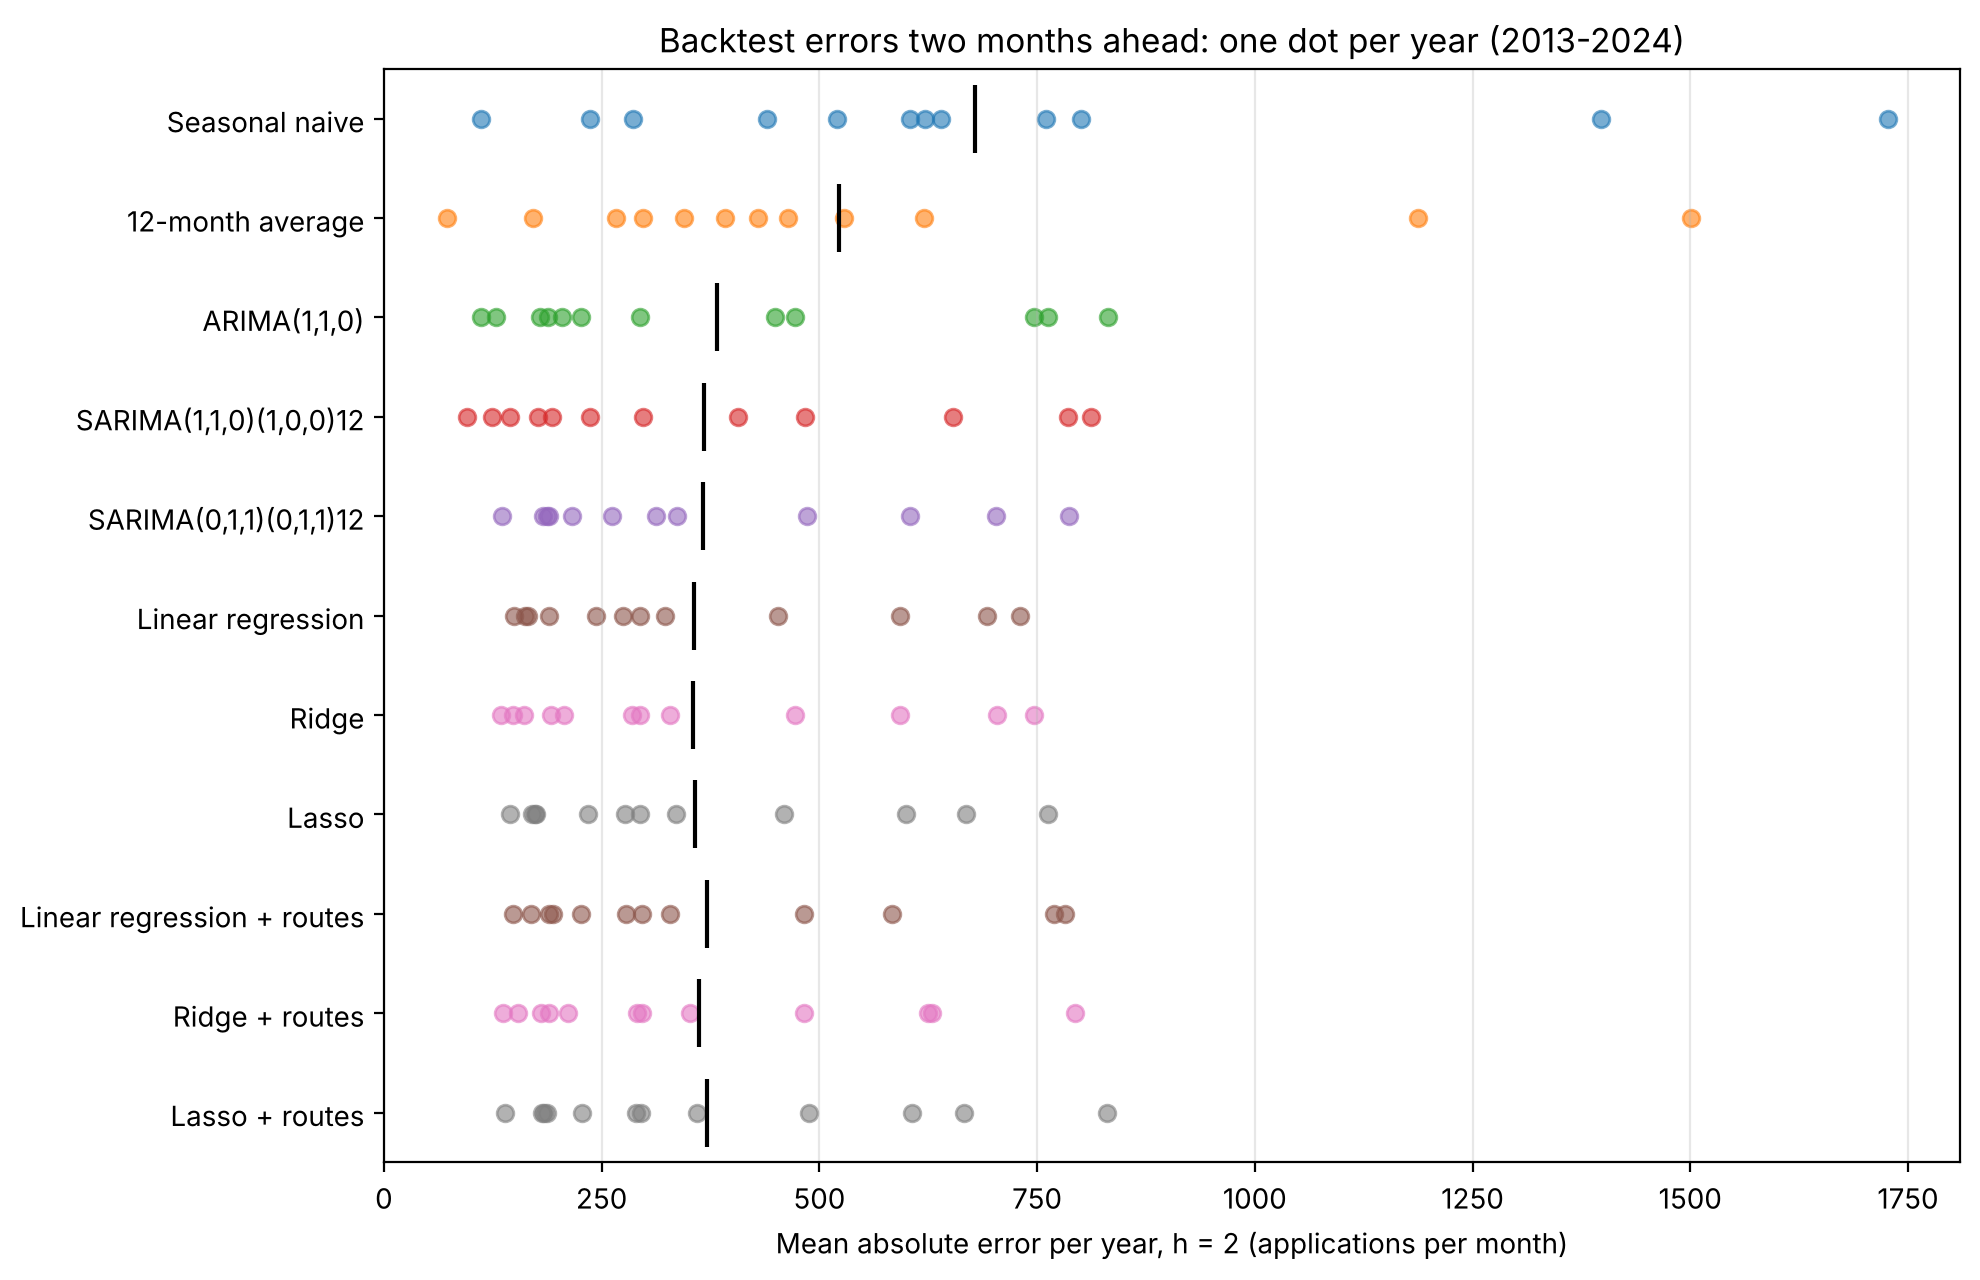

In [9]:
fig, ax = plt.subplots(figsize=(10, 6.5))
for i, name in enumerate(model_order):
    errors_by_year = by_year[name]
    ax.scatter(errors_by_year, [i] * len(errors_by_year), alpha=0.6, color=colors[name])
    ax.scatter([errors_by_year.mean()], [i], marker="|", s=600, color="black")
ax.set_yticks(range(len(model_order)))
ax.set_yticklabels(model_order)
ax.invert_yaxis()
ax.set_xlim(left=0)
ax.set_xlabel("Mean absolute error per year, h = 2 (applications per month)")
ax.set_title("Backtest errors two months ahead: one dot per year (2013-2024)")
ax.grid(axis="x", alpha=0.3)
plt.tight_layout()
plt.savefig("../output/figures/03_errors_by_year_h2.png")
plt.show()

**What we see.**
- **Best model against best baseline:** Ridge has a lower MAE than the 12-month average in 8 of 12 years. The gap between their averages (167) is smaller than the spread across years (standard deviation 417 and 220). In the picture, the two dots far to the right of the 12-month average (about 1,190 and 1,500) are the years 2016 and 2015 (table above).
- **Best regression against best SARIMA:** Ridge is lower in 9 of 12 years, but the gap between the averages is only 11 persons, against a spread across years of about 220. Several of its wins are tiny (2019: 135 against 136; 2013: 207 against 216), and it loses in 2016, 2020 and 2021.
- In the picture, the six own-history models look almost the same: their averages (black bars) lie close together, between about 358 and 388. The three rows "+ routes" look very similar to the rows of the same models without the indicator.

**What this means for us.** The advantage of the own-history models over the simple rules is consistent, but it comes mostly from the years with big changes. Among the six own-history models, the differences are within the noise. When we choose the final model before the test period, a simpler model within the noise is a serious candidate (notebook 209, Step 7).

## 6. Errors over the horizon

How fast do the errors grow when we forecast further ahead? We plot the MAE of each model for $h = 1, 2, 3$.

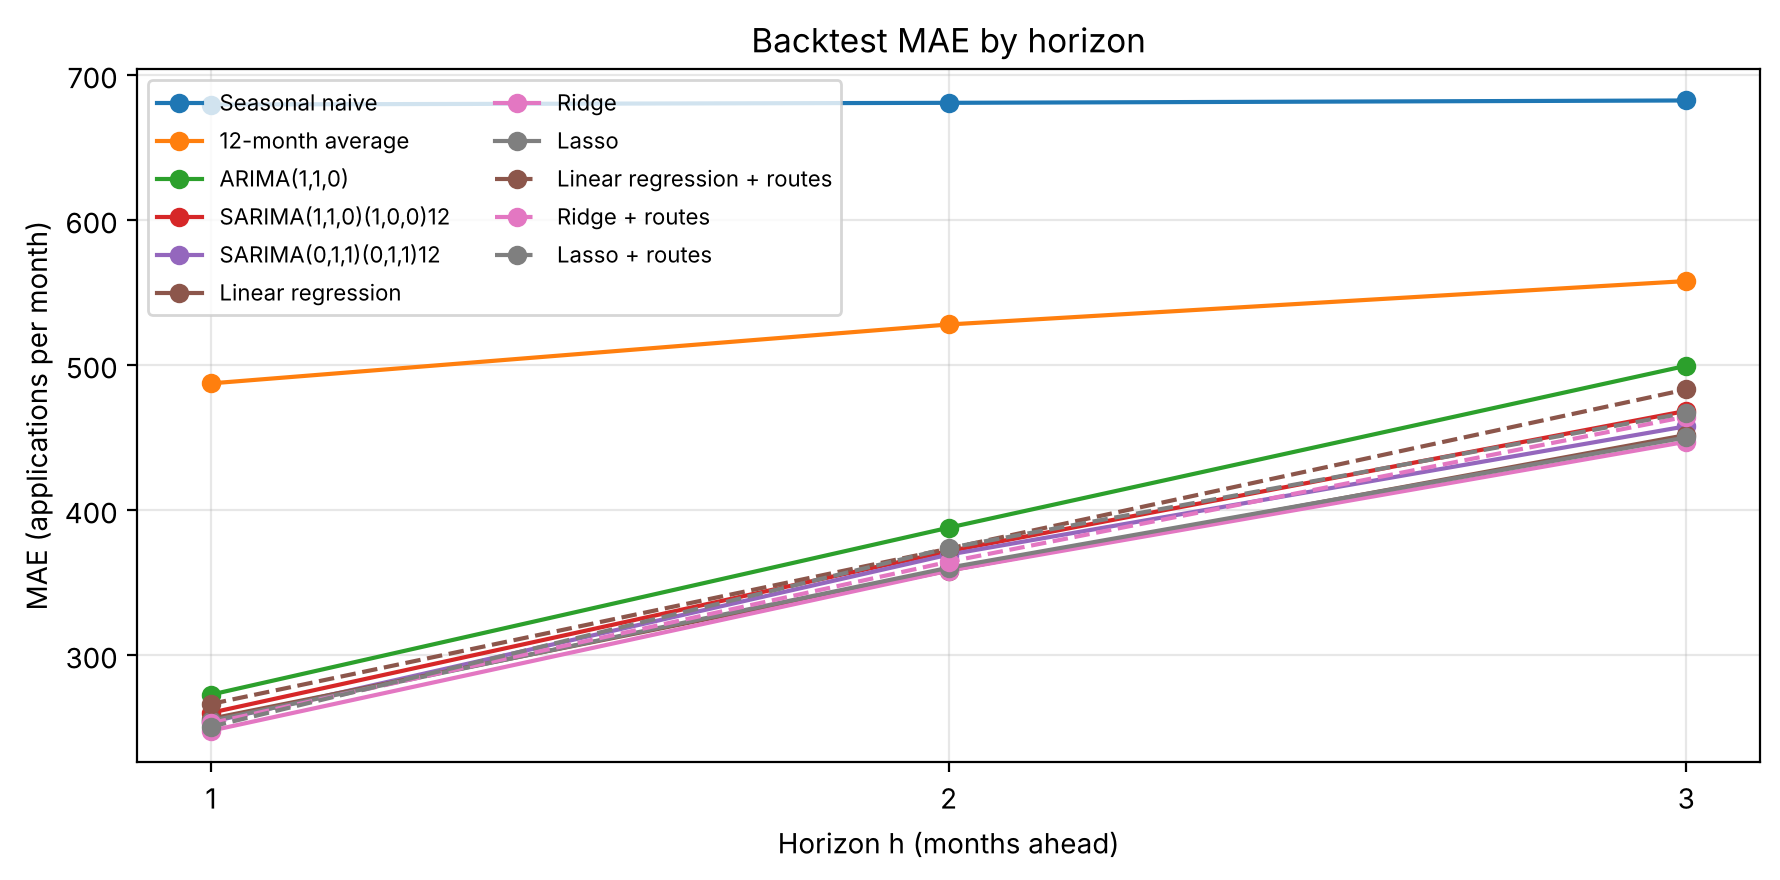

In [10]:
fig, ax = plt.subplots(figsize=(9, 4.5))
for i, name in enumerate(model_order):
    one = errors[errors["model"] == name]
    style = "--" if name in indicator_models else "-"
    ax.plot(one["h"], one["MAE (persons)"], marker="o", linestyle=style, color=colors[name], label=name)
ax.set_xticks([1, 2, 3])
ax.set_xlabel("Horizon h (months ahead)")
ax.set_ylabel("MAE (applications per month)")
ax.set_title("Backtest MAE by horizon")
ax.legend(fontsize=8, ncol=2)
ax.grid(alpha=0.3)
plt.tight_layout()
plt.savefig("../output/figures/03_mae_by_horizon.png")
plt.show()

**What we see.** For the six own-history models, the MAE grows steadily from about 250 at $h = 1$ to about 450 to 500 at $h = 3$, as expected: the further ahead, the less the recent months tell us (notebook 202). Ridge is lowest at every horizon (248, 358, 447), but the lines of the regressions and the SARIMA models almost overlap. The dashed lines (models with the route indicator) lie slightly above the lines of the same models without it, most visibly at $h = 3$. ARIMA(1,1,0), without a seasonal part, falls behind at $h = 3$ (499). The 12-month average grows more slowly (487 to 558), and the seasonal naive stays flat at about 680.

## 7. Does the route indicator help?

Our project plan adds the indicator block **one block at a time**: the models of `02c` are exactly those of `02b` plus two route features. So we compare each regression with its own "+ routes" version, on the same forecast months. We use the rule of our project plan: a change counts as a clear improvement only if it lowers the MAE by at least 10%.

In [11]:
rows = []
for name in regression_models:
    for h in [1, 2, 3]:
        without = errors[(errors["model"] == name) & (errors["h"] == h)].iloc[0]
        with_routes = errors[(errors["model"] == name + " + routes") & (errors["h"] == h)].iloc[0]
        rows.append({
            "model": name, "h": h,
            "MAE without routes": without["MAE (persons)"],
            "MAE with routes": with_routes["MAE (persons)"],
            "change in MAE (%)": 100 * (with_routes["MAE (persons)"] / without["MAE (persons)"] - 1),
            "RMSE (log) without": without["RMSE (log)"],
            "RMSE (log) with": with_routes["RMSE (log)"],
        })
indicator_effect = pd.DataFrame(rows).set_index(["model", "h"])
indicator_effect.to_csv("../output/tables/03_indicator_effect.csv")
indicator_effect.round(3)

MAE without routes  MAE with routes  change in MAE (%)  \
model             h                                                           
Linear regression 1             255.864          266.060              3.985   
                  2             358.007          373.149              4.229   
                  3             451.512          482.932              6.959   
Ridge             1             247.610          252.808              2.099   
                  2             357.949          364.084              1.714   
                  3             446.888          464.199              3.874   
Lasso             1             254.440          250.398             -1.589   
                  2             359.976          373.622              3.791   
                  3             449.834          466.779              3.767   

                     RMSE (log) without  RMSE (log) with  
model             h                                       
Linear regression 1               0.197            0.203  
                  2               0.278            0.282  
                  3               0.333            0.340  
Ridge             1               0.187            0.191  
                  2               0.279            0.281  
                  3               0.336            0.340  
Lasso             1               0.193            0.190  
                  2               0.281            0.285  
                  3               0.338            0.345

**What we see.**
- At the main horizon $h = 2$, all three regressions get **worse** with the route indicator: the MAE goes up by 1.7% (Ridge), 3.8% (Lasso) and 4.2% (linear regression). At $h = 3$ the loss is larger (3.8% to 7.0%).
- The only gain is Lasso at $h = 1$: 250.4 instead of 254.4 persons (−1.6%), and also a slightly lower RMSE (log) (0.190 against 0.193). Ridge and the linear regression are worse at $h = 1$ too.
- The RMSE (log) tells the same story: with the routes it is higher in 8 of the 9 cases.
- No change comes close to the 10% improvement of our success rule.

**What this means for us.** The route indicator, as we can use it at the cutoff, does not improve the forecasts. This fits what we found in `01b_preprocess_indicators.ipynb`: the change on the routes moved together with the change in applications in the same month and one month later (correlations 0.31 and 0.35), but hardly at all from two months on (0.08 or less). Because Frontex is published one month later than the target, the newest route month we may use lies at least $h + 1$ months before the forecast month, so the useful part of the signal arrives too late.

The same comparison year by year and by period, at the main horizon $h = 2$ (as in sections 4 and 5).

In [12]:
for name in regression_models:
    with_routes = name + " + routes"
    wins = (by_year[with_routes] < by_year[name]).sum()
    gap = by_year[name].mean() - by_year[with_routes].mean()
    print(f"{with_routes:27s} lower MAE than {name:18s} in {wins:2d} of {by_year.shape[0]} years | "
          f"gap of the averages {gap:6.1f} | spread across years {by_year[name].std():.0f}")
print()
by_period.pivot(index="model", columns="period", values="MAE (persons)").loc[regression_models + indicator_models, list(periods)].round(0)

Linear regression + routes  lower MAE than Linear regression  in  3 of 12 years | gap of the averages  -14.8 | spread across years 210
Ridge + routes              lower MAE than Ridge              in  2 of 12 years | gap of the averages   -6.2 | spread across years 220
Lasso + routes              lower MAE than Lasso              in  3 of 12 years | gap of the averages  -13.3 | spread across years 214



period,all backtest months,without 2015-16 and 2020,from 2022
model,,,
Linear regression,358.0,286.0,413.0
Ridge,358.0,282.0,415.0
Lasso,360.0,288.0,420.0
Linear regression + routes,373.0,291.0,412.0
Ridge + routes,364.0,292.0,436.0
Lasso + routes,374.0,297.0,431.0


In [13]:
# Year by year at h = 2: MAE of Ridge without and with the routes, and the difference
ridge_years = by_year[["Ridge", "Ridge + routes"]].copy()
ridge_years["with minus without"] = ridge_years["Ridge + routes"] - ridge_years["Ridge"]
ridge_years

,Ridge,Ridge + routes,with minus without
year,,,
2013,207.0,211.0,4.0
2014,472.0,482.0,10.0
2015,704.0,629.0,-75.0
2016,746.0,794.0,48.0
2017,161.0,180.0,19.0
2018,148.0,154.0,6.0
2019,135.0,137.0,2.0
2020,285.0,291.0,6.0
2021,192.0,190.0,-2.0


**What we see.**
- Year by year at $h = 2$, the versions with the routes are better in only 2 or 3 of the 12 years. The gaps of the averages (6 to 15 persons, in favour of the models *without* the routes) are small compared with the spread across years (about 210 to 220).
- For Ridge, the one year with a clear gain is **2015**, the start of the big crisis: 629 instead of 704 (−75). But in 2016 the routes made the forecasts worse (+48), and also in 2022 and 2023 (+23 and +32). In the other years the differences are small (between −2 and +19).
- Without 2015-16 and 2020, all three models are worse with the routes (291 to 297 against 282 to 288).

**What this means for us.** The loss from adding the routes is small and within the noise, but there is no sign of a gain either, except in 2015. One good year is not enough to choose a model (notebook 209: we look at all folds, not at the best one). Following our plan (one block at a time, keep it only if it helps), **we do not keep the route indicator in the final model**. We report this as a result: for forecasts two months ahead, the past of the Swiss series itself already contains what the routes tell us in time.

## Summary

- **Main comparison ($h = 2$):** best simple baseline = 12-month average (MAE 528 persons); best model = Ridge (MAE 358 persons): **32% lower MAE**, 18% lower RMSE (log).
- **Regressions against SARIMA:** practically equal. Ridge is 3% lower by MAE but slightly worse by RMSE (log); it wins in 9 of 12 years, mostly by small margins; the gap (11 persons) is tiny compared with the spread across years.
- **Robustness:** the own-history models beat the simple rules in all periods, but the advantage is smaller without 2015-16 and 2020, and the best own-history model changes with the period.
- **Route indicator (one block at a time):** adding the detections on the three routes to the regressions makes the MAE at $h = 2$ 1.7% to 4.2% higher; the models with the routes win in only 2 or 3 of 12 years. The only clear gain is in 2015. We do not keep the indicator: it is published too late to help at our cutoff.
- **Next steps:** the final model is chosen among the own-history models, on the backtest only; then we use the test period, once.